# Statistical Learning in Macro Portfolio Allocation

Macro-quantamental information has a plausible and documented bearing on the returns of all major asset classes. Excess inflation weighs on bonds, growth above trend supports equities, and rate differentials pay currency carry. This notebook applies that information to a basic portfolio decision, the allocation of capital across eleven asset classes and cash. Two signals are compared under the same allocation rule. A theory-guided signal combines 36 macro themes with signs set by economic reasoning. A learning-based signal comes from an ensemble of 35 regression models that sequentially select and weight 74 macro factors for each asset class.

Both macro-based allocations have produced material value against an equal-weight benchmark. Since October 2004 the theory-guided allocation has posted a Sharpe ratio of 0.61, against 0.53 for the learned allocation and 0.52 for equal weights. The learned allocation has thus been a slight improvement on equal weights, with marginally higher risk-adjusted and compounded returns and the shallowest drawdown of the three. Both macro allocations have reduced the correlation with US equities from 0.77 to about 0.58. The theory-guided score has displayed significant predictive power for next-quarter returns, with a Kendall rank correlation of 0.059 at a probability of significance above 99%. The return advantage has been concentrated in the years before 2010. Since mid-2010 the theory-guided allocation has matched equal weights on Sharpe ratio, which makes its main lasting value a lower dependence on equity markets.

Data come from BIS, OECD, Eurostat and ECB country exports, plus FRED, EIA and Yahoo Finance series pulled live by the first data cell (135 FRED series and 30 ETFs). Macro inputs are current revisions shifted by approximate publication lags rather than point-in-time vintages, so backtests are indicative of signal quality rather than of real-time performance.

## The basic idea

The allocation process runs from raw data to portfolio weights in seven stages.

1. **Targets.** Each of eleven asset classes is represented by a daily USD excess return, the return over cash.
2. **Macro factors.** Country series are transformed into economic factors such as excess inflation, growth relative to trend, real rates, credit growth, carry and survey levels.
3. **Geographic composites.** Factors are averaged across countries with GDP weights into global, developed, emerging and asset-class baskets.
4. **Scores.** Each composite is normalized against its own history, so that factors with different units become comparable.
5. **Theory-guided signal.** Scores are combined into macro themes, and themes into one support score per asset class.
6. **Learning-based signal.** For each asset class, an ensemble of regression models learns which factors have predicted next month's return, with quarterly re-estimation on data available at the time.
7. **Allocation.** Either signal is translated into portfolio weights through a softmax rule that includes cash, with quarterly rebalancing.

In [1]:
import os
import sys
import warnings
from pathlib import Path

# keep library notices (and the local paths they print) out of the outputs
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", category=DeprecationWarning)

import macrosynergy.learning as msl
import macrosynergy.management as msm
import macrosynergy.panel as msp
import macrosynergy.pnl as msn
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import make_scorer
from sklearn.pipeline import Pipeline

sys.path.insert(0, os.environ.get("STUDY_DIR") or str(Path.cwd()))
import allocation_data as ad

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.simplefilter("ignore", DeprecationWarning)  # pandas notices re-enabled by imports
pd.set_option("display.width", 160)

RNG_COLS = ["cid", "xcat", "real_date", "value"]
START_DATE = "2004-01-01"
ASSET_CLASSES = list(ad.SLEEVES)
AC_LABELS = {
    "USEQ": "US equities", "DXEQ": "Developed ex-US equities",
    "EMEQ": "Emerging equities", "USDU": "US Treasuries (5-year)",
    "DXDU": "Developed ex-US government bonds", "DXFX": "Developed FX vs USD",
    "G2CR": "US credit", "EMCR": "Emerging hard-currency debt",
    "EMLC": "Emerging local-currency bonds", "MTL": "Industrial metals", "GLD": "Gold",
}

## Targets

### USD excess returns

All targets are daily USD excess returns, i.e. returns minus a cash accrual at the prior day's federal funds rate. Five asset classes are constructed from their economic drivers. US Treasuries (USDU) are a constant-maturity 5-year bond priced from the daily 5-year yield. Developed-market credit (G2CR) adds Baa spread carry and spread changes to that bond. Developed-market FX (DXFX) is an equal-weighted basket of nine currency forwards against the dollar, each earning the spot change plus the policy-rate differential. Developed and emerging equities (DXEQ, EMEQ) are equal-weighted baskets of 7 and 12 country ETFs, live once three members trade. The other six asset classes use one ETF each.

Five asset classes have histories from the 1990s. Developed government bonds, emerging credit and metals start in 2007 and emerging local-currency bonds in 2010, as free sources lack longer daily histories. The emerging equity basket holds only three countries until about 2000. A live mask prevents any allocation to an asset class before it trades.

The first code cell refreshes the data. It compares the latest saved snapshot with `Macro Data Extract/requests.csv` and pulls any missing series. API keys are read from the local `API Key.xlsx` and are never printed.

Learning targets are vol-targeted returns, i.e. returns scaled to 10% annualized volatility based on a 261-day volatility estimate. Without this scaling, regressions would be dominated by the most volatile asset classes.

In [2]:
# Pull any series in Macro Data Extract/requests.csv that the latest snapshot
# lacks. Keys are read locally by the gatherer and never printed. Set
# REFRESH_DATA = False to run on the existing snapshot only.
REFRESH_DATA = True
if REFRESH_DATA:
    ad.refresh_data()

df_xr, cash_accrual, etf_closes = ad.load_market(sleeves="matched")
print("sleeves rebuilt from yields, spreads or baskets:", ", ".join(ad.BUILT_SLEEVES))
dfx = df_xr.copy()

# Zero excess return for the cash sleeve keeps it in the PnL universe.
cash_rows = pd.DataFrame({
    "cid": "CASH", "xcat": "XR_NSA",
    "real_date": sorted(df_xr["real_date"].unique()),
})
cash_rows["value"] = 0.0
dfx = msm.update_df(dfx, cash_rows[RNG_COLS])

# The US equity excess-return ticker doubles as the PnL benchmark.

dfa = msp.historic_vol(
    dfx, xcat="XR_NSA", cids=ASSET_CLASSES,
    lback_periods=261, lback_meth="ma", est_freq="m", postfix="ASD",
)
dfx = msm.update_df(dfx, dfa)
dfa = msp.panel_calculator(
    dfx, calcs=["XRVT = XR_NSA * 10 / XR_NSAASD"], cids=ASSET_CLASSES
)
dfx = msm.update_df(dfx, dfa)

live_start = (
    df_xr.groupby("cid")["real_date"].min()
    .reindex(ASSET_CLASSES).rename("first return")
)
print(live_start.to_string())

snapshot up to date: 20261119T014653580694Z
sleeves rebuilt from yields, spreads or baskets: DXEQ, DXFX, EMEQ, G2CR, USDU
cid
USEQ   1993-02-01
DXEQ   1996-03-19
EMEQ   1996-03-19
USDU   1990-01-02
DXDU   2007-10-12
DXFX   1990-01-02
G2CR   1990-01-02
EMCR   2007-12-20
EMLC   2010-07-26
MTL    2007-01-08
GLD    2004-11-19


## Features

### Theory-guided factors

#### Factor calculations

Theory-guided factors are economic quantities with a plausible link to asset returns. Inflation above the central bank target is negative for bonds, growth above trend is positive for equities, and a wide policy-rate differential to the dollar supports currency carry. Each factor is calculated from country series with fixed formulas and lagged by its typical publication delay.

Two data rules apply. The three BIS credit measures, i.e. the credit gap, the credit-to-GDP ratio and the credit level, are kept separate, and credit growth is defined as the annual change in credit relative to GDP. Emerging-market observations before 1996 are excluded, since hyperinflation values would distort the scoring scale for decades.

The chart below shows the number of economies covered by each factor category. Exchange-rate, policy-rate, property, credit and survey factors cover 23 to 36 economies. Industrial production and retail sales cover only 14, as only Eurostat and FRED supply local histories. Many US factors are single-country, so global composites lean towards the US economy.

In [3]:
df_cats = ad.build_categories()
coverage = df_cats.groupby("xcat")["cid"].nunique().sort_values(ascending=False)
print(f"{coverage.size} factor categories, {df_cats['cid'].nunique()} economies")
print(coverage.to_string())

55 factor categories, 36 economies
xcat
REER_YOY         36
REER_V5Y         36
REERAPPR_1M      36
XHPI             35
NGDPUSD          34
FXCARRY          33
CREDITGAP        32
CREDITGDP_D4Q    32
BCONF_LVL        30
BCONF_D3M        30
CCONF_D3M        27
CCONF_LVL        27
CPIH_YOY         24
RIRY             24
XCPIB_PAR        24
RFXCARRY         23
CLI_D3M          17
CLI_LVL          17
IP_YOY3M         14
XRPCONS          14
XIP              14
UNEMP_V5YMM      14
UNEMP_D12M       14
RGDP_YOY         14
TERMSPRD         13
XMONGROWTH        4
CABGDP            3
HHDSR_D4Q         1
GB10Y_YLD         1
GB05Y_YLD         1
GB02Y_YLD         1
CRSPRDBAA         1
CSENT_D3M         1
BLSTIGHT          1
BLSTIGHTS         1
FCI               1
DXY_MOM3M         1
DU05YETP          1
CSENT_V5YMM       1
SLOPE10Y3M        1
SLOPE10Y2Y        1
METALPX_MOM3M     1
INFE5Y5YRAW       1
ISRATIO_D3M       1
INFE5YRAW         1
NIIPTREND         1
XBTREND           1
XHHINFE           1


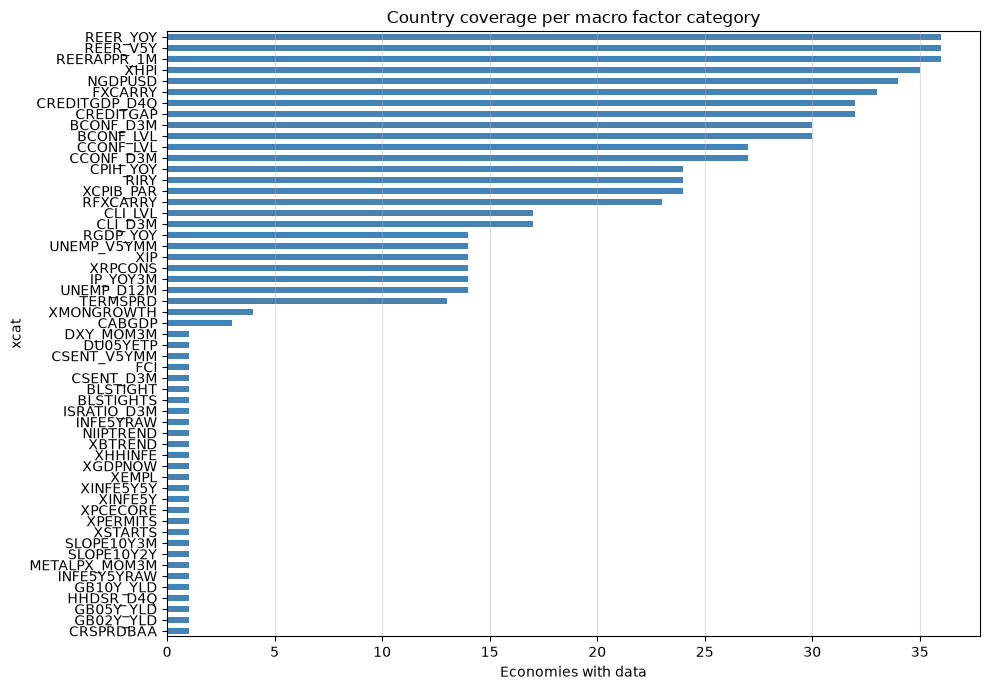

In [4]:
fig, ax = plt.subplots(figsize=(10, 7))
coverage.sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_title("Country coverage per macro factor category")
ax.set_xlabel("Economies with data")
ax.grid(axis="x", alpha=0.4)
plt.tight_layout()
plt.show()

#### Geographic composites

Country factors are averaged over country sets: global, developed ex-US, emerging, and the countries underlying each asset class. Weights are nominal GDP in USD, applied 18 months after the end of each year, roughly when the data become available. The euro area enters through Germany, France, Italy, the Netherlands and Spain. The euro aggregate is used only for policy-rate and money factors, whose national histories end in 1998, and these baskets use equal weights.

In [5]:
DM_EX_US = ["AUD", "CAD", "CHF", "GBP", "JPY", "NOK", "NZD", "SEK",
            "DEM", "FRF", "ITL", "NLG", "ESP"]
EM = ["BRL", "CLP", "CNY", "COP", "CZK", "HUF", "IDR", "ILS", "INR", "KRW",
      "MXN", "MYR", "PEN", "PHP", "PLN", "RON", "SGD", "THB", "TRY", "TWD", "ZAR"]
EUR_KEEP = {"RIRY", "XMONGROWTH", "XCPIB_PAR"}  # EUR-level-only inputs
GLOBAL = ["USD"] + DM_EX_US + EM


def basket(xcat: str, members: list[str]) -> list[str]:
    available = set(df_cats.loc[df_cats["xcat"] == xcat, "cid"])
    chosen = [cid for cid in members if cid in available]
    if xcat in EUR_KEEP and "EUR" in available and "EUR" not in chosen:
        chosen.append("EUR")
    return chosen


AGGREGATES = [
    ("GLB", "XIP", GLOBAL), ("GLB", "XRPCONS", GLOBAL), ("GLB", "RIRY", GLOBAL),
    ("GLB", "XMONGROWTH", GLOBAL), ("GLB", "BCONF_LVL", GLOBAL),
    ("GLB", "BCONF_D3M", GLOBAL), ("GLB", "CCONF_D3M", GLOBAL),
    ("GLB", "CLI_LVL", GLOBAL), ("GLB", "CLI_D3M", GLOBAL),
    ("GLB", "CREDITGDP_D4Q", GLOBAL), ("GLB", "XCPIB_PAR", GLOBAL),
    ("GLB", "UNEMP_D12M", GLOBAL), ("GLB", "UNEMP_V5YMM", GLOBAL),
    ("DXEQ", "XRPCONS", DM_EX_US), ("DXEQ", "XCPIB_PAR", DM_EX_US),
    ("DXEQ", "XIP", DM_EX_US),
    ("DXDU", "XHPI", DM_EX_US), ("DXDU", "XRPCONS", DM_EX_US),
    ("DXDU", "XMONGROWTH", DM_EX_US),
    ("DMFX", "IP_YOY3M", DM_EX_US), ("DMFX", "REER_YOY", DM_EX_US),
    ("EMEQ", "CABGDP", EM), ("EMEQ", "XCPIB_PAR", EM),
    ("EMEQ", "CREDITGDP_D4Q", EM),
    ("EMLC", "XCPIB_PAR", EM), ("EMLC", "RIRY", EM),
    ("EMLC", "REERAPPR_1M", EM), ("EMLC", "REER_YOY", EM),
    ("DMCR", "XHPI", ["USD", "DEM", "FRF", "ITL", "NLG", "ESP"]),
    # carry, valuation, credit-gap and term-spread blocks
    ("GLB", "CREDITGAP", GLOBAL), ("DXEQ", "CREDITGAP", DM_EX_US),
    ("EMEQ", "CREDITGAP", EM), ("DXDU", "RIRY", DM_EX_US),
    ("DXDU", "TERMSPRD", DM_EX_US),
    ("DMFX", "FXCARRY", DM_EX_US), ("DMFX", "RFXCARRY", DM_EX_US),
    ("DMFX", "REER_V5Y", DM_EX_US),
    ("EMFX", "FXCARRY", EM), ("EMFX", "RFXCARRY", EM), ("EMFX", "REER_V5Y", EM),
]

aggregate_parts = []
# GDP weights whenever every member has nominal GDP in
# USD; otherwise equal weights. Weights renormalise over members with data.
gdp_wide = df_cats[df_cats["xcat"] == "NGDPUSD"].pivot(
    index="real_date", columns="cid", values="value")
weighting = {"gdp": 0, "equal": 0}


def gdp_weighted(xcat: str, chosen: list[str], geo: str) -> pd.DataFrame | None:
    if not set(chosen) <= set(gdp_wide.columns):
        return None
    vals = df_cats[(df_cats["xcat"] == xcat) & df_cats["cid"].isin(chosen)].pivot(
        index="real_date", columns="cid", values="value")
    wgt = gdp_wide.reindex(vals.index).ffill()[vals.columns].where(vals.notna())
    value = (vals * wgt).sum(axis=1) / wgt.sum(axis=1)
    value = value[wgt.sum(axis=1) > 0].dropna()
    return pd.DataFrame({"cid": geo, "xcat": xcat, "real_date": value.index,
                         "value": value.values})


for geo, xcat, members in AGGREGATES:
    chosen = basket(xcat, members)
    if len(chosen) < 2:
        print(f"{geo}/{xcat}: fewer than two members, skipped")
        continue
    dfa = gdp_weighted(xcat, chosen, geo)
    if dfa is None:
        dfa = msp.linear_composite(
            df=df_cats[df_cats["xcat"] == xcat], xcats=xcat, cids=chosen,
            new_cid=geo, complete_cids=False,
        )
        weighting["equal"] += 1
    else:
        weighting["gdp"] += 1
    aggregate_parts.append(dfa[RNG_COLS])
print("basket weighting:", weighting)

df_facts = pd.concat([df_cats] + aggregate_parts, ignore_index=True)

# Relative factors: DM FX industrial production versus the US.
wide_ip = df_facts[df_facts["xcat"] == "IP_YOY3M"].pivot(
    index="real_date", columns="cid", values="value"
)
if {"DMFX", "USD"} <= set(wide_ip.columns):
    rel = (wide_ip["DMFX"] - wide_ip["USD"]).dropna()
    df_facts = pd.concat([df_facts, pd.DataFrame({
        "cid": "DMFX", "xcat": "IPVUSD", "real_date": rel.index, "value": rel.values,
    })], ignore_index=True)

print(f"{len(df_facts):,} factor rows across "
      f"{df_facts.groupby(['cid', 'xcat']).ngroups} country-factor series")

basket weighting: {'gdp': 28, 'equal': 12}
5,583,017 factor rows across 690 country-factor series


#### Factor scores

Factors are expressed in different units, from percentage points of inflation to confidence index levels. Each composite is therefore normalized against its own history with zero-neutral z-scores. The scale is the median absolute deviation, re-estimated monthly, which is less sensitive to outliers than the standard deviation. Scores are winsorized at ±3 and start after five years of history. Zero-neutrality preserves the meaning of zero: a score is positive only if inflation is above target or growth above trend, not merely above its historical average.

In [6]:
# The facts used downstream: geography aggregates plus the US single-country menu.
FACT_TICKERS = [
    ("GLB", "XIP"), ("GLB", "XRPCONS"), ("GLB", "RIRY"), ("GLB", "XMONGROWTH"),
    ("GLB", "BCONF_LVL"), ("GLB", "BCONF_D3M"), ("GLB", "CCONF_D3M"),
    ("GLB", "CLI_LVL"), ("GLB", "CLI_D3M"), ("GLB", "CREDITGDP_D4Q"),
    ("GLB", "XCPIB_PAR"), ("GLB", "UNEMP_D12M"), ("GLB", "UNEMP_V5YMM"),
    ("DXEQ", "XRPCONS"), ("DXEQ", "XCPIB_PAR"), ("DXEQ", "XIP"),
    ("DXDU", "XHPI"), ("DXDU", "XRPCONS"), ("DXDU", "XMONGROWTH"),
    ("DMFX", "IPVUSD"), ("DMFX", "REER_YOY"),
    ("EMEQ", "CABGDP"), ("EMEQ", "XCPIB_PAR"), ("EMEQ", "CREDITGDP_D4Q"),
    ("EMLC", "XCPIB_PAR"), ("EMLC", "RIRY"), ("EMLC", "REERAPPR_1M"),
    ("EMLC", "REER_YOY"), ("DMCR", "XHPI"),
    ("USD", "XIP"), ("USD", "XRPCONS"), ("USD", "XCPIB_PAR"), ("USD", "XHPI"),
    ("USD", "RIRY"), ("USD", "XMONGROWTH"), ("USD", "XGDPNOW"),
    ("USD", "DU05YETP"), ("USD", "XINFE5Y"), ("USD", "XINFE5Y5Y"),
    ("USD", "XHHINFE"), ("USD", "XPCECORE"), ("USD", "XEMPL"),
    ("USD", "UNEMP_D12M"), ("USD", "UNEMP_V5YMM"), ("USD", "CSENT_D3M"),
    ("USD", "CSENT_V5YMM"), ("USD", "ISRATIO_D3M"), ("USD", "XBTREND"),
    ("USD", "NIIPTREND"), ("USD", "CABGDP"), ("USD", "FCI"),
    ("USD", "SLOPE10Y2Y"), ("USD", "SLOPE10Y3M"), ("USD", "CRSPRDBAA"),
    ("USD", "GB02Y_YLD"), ("USD", "GB05Y_YLD"), ("USD", "GB10Y_YLD"),
    ("USD", "DXY_MOM3M"), ("USD", "METALPX_MOM3M"), ("USD", "CREDITGDP_D4Q"),
    ("USD", "XHPI"), ("USD", "BCONF_LVL"), ("USD", "BCONF_D3M"),
    ("USD", "CLI_LVL"), ("USD", "CLI_D3M"),
    ("GLB", "CREDITGAP"), ("DXEQ", "CREDITGAP"), ("EMEQ", "CREDITGAP"),
    ("DXDU", "RIRY"), ("DXDU", "TERMSPRD"),
    ("DMFX", "FXCARRY"), ("DMFX", "RFXCARRY"), ("DMFX", "REER_V5Y"),
    ("EMFX", "FXCARRY"), ("EMFX", "RFXCARRY"), ("EMFX", "REER_V5Y"),
    ("USD", "CREDITGAP"), ("USD", "BLSTIGHT"), ("USD", "BLSTIGHTS"),
    ("USD", "HHDSR_D4Q"), ("USD", "XPERMITS"), ("USD", "XSTARTS"),
]
FACT_TICKERS = sorted(set(FACT_TICKERS))

available_pairs = set(map(tuple, df_facts[["cid", "xcat"]].drop_duplicates().values))
facts = [(cid, xcat) for cid, xcat in FACT_TICKERS if (cid, xcat) in available_pairs]
missing = [pair for pair in FACT_TICKERS if pair not in available_pairs]
if missing:
    print(f"unavailable fact series skipped: {missing}")

score_parts = []
MIN_SCORE_DAYS = 5 * 261 + 60  # five years of history plus an estimation buffer
counts = df_facts.groupby(["cid", "xcat"])["value"].size()
for xcat in sorted({xcat for _, xcat in facts}):
    cids = sorted(
        cid for cid, x in facts
        if x == xcat and counts.get((cid, xcat), 0) >= MIN_SCORE_DAYS
    )
    skipped = sorted({cid for cid, x in facts if x == xcat} - set(cids))
    if skipped:
        print(f"{xcat}: insufficient history to score {skipped}")
    if not cids:
        continue
    dfa = msp.make_zn_scores(
        df=df_facts[df_facts["xcat"] == xcat], xcat=xcat, cids=cids,
        neutral="zero", thresh=3, est_freq="M", min_obs=5 * 261,
        pan_weight=0, postfix="_ZN",
    )
    score_parts.append(dfa[RNG_COLS])
df_scores = pd.concat(score_parts, ignore_index=True)
print(f"{df_scores.groupby(['cid', 'xcat']).ngroups} scored fact series")

XGDPNOW: insufficient history to score ['USD']
80 scored fact series


#### U.S. directional factors

Two U.S. directional factors are built from scored components. Labor market tightness combines excess employment growth (weight 0.5), the annual change in the unemployment rate (−0.25) and the unemployment rate relative to its five-year median (−0.25). Relative dollar strength averages three differentials between the US and the rest of the world: real rates, industrial growth and the external balance. A high value indicates dollar strength and headwinds for non-USD assets.

In [7]:
def score_series(series: pd.Series, cid: str, xcat: str) -> pd.DataFrame:
    series = series.dropna()
    if len(series) < 5 * 261 + 60:
        raise ValueError(f"{cid}_{xcat}: only {len(series)} days, cannot score")
    frame = pd.DataFrame({
        "cid": cid, "xcat": xcat, "real_date": series.index, "value": series.values,
    }).dropna()
    return msp.make_zn_scores(
        df=frame, xcat=xcat, cids=[cid], neutral="zero", thresh=3,
        est_freq="M", min_obs=5 * 261, pan_weight=0, postfix="_ZN",
    )[RNG_COLS]


wide_scores = df_scores.assign(
    ticker=df_scores["cid"] + "_" + df_scores["xcat"]
).pivot(index="real_date", columns="ticker", values="value")

labtight = (
    0.5 * wide_scores["USD_XEMPL_ZN"]
    - 0.25 * wide_scores["USD_UNEMP_D12M_ZN"]
    - 0.25 * wide_scores["USD_UNEMP_V5YMM_ZN"]
).dropna()

wide_riry = df_facts[df_facts["xcat"] == "RIRY"].pivot(
    index="real_date", columns="cid", values="value"
)
wide_xip = df_facts[df_facts["xcat"] == "XIP"].pivot(
    index="real_date", columns="cid", values="value"
)
usddir_parts = [
    score_series((wide_riry["USD"] - wide_riry["GLB"]).dropna(), "USD", "RIRYVGLB"),
    score_series((wide_xip["USD"] - wide_xip["GLB"]).dropna(), "USD", "XIPVGLB"),
    df_scores[(df_scores["cid"] == "USD") & (df_scores["xcat"] == "CABGDP_ZN")],
]
usddir_wide = pd.concat(usddir_parts, ignore_index=True).assign(
    ticker=lambda d: d["xcat"]
).pivot(index="real_date", columns="ticker", values="value")
usddir = usddir_wide.mean(axis=1).dropna()

df_scores = pd.concat([
    df_scores,
    score_series(labtight, "USD", "LABTIGHT"),
    score_series(usddir, "USD", "USDDIR"),
], ignore_index=True)

### Broad factor set for learning

#### Feature availability and correlation filters

The learning-based signal uses a broad set of scored factors and selects from them without prior judgement. A factor qualifies if it has at least 60 live month-ends and non-trivial variation. Where two factors correlate above 0.95 over 60 or more common months, the one with the shorter history is removed. Of 80 scored factors, 74 pass these filters and eight are removed as near-duplicates, such as the 5-year and 2-year Treasury yields and the two US bank lending survey measures. All asset-class models use the same 74 features, so each can respond differently to the same global information.

In [8]:
tickers = df_scores.assign(ticker=df_scores["cid"] + "_" + df_scores["xcat"])
wide_daily = tickers.pivot(index="real_date", columns="ticker", values="value")
month_ends = wide_daily.groupby(
    [wide_daily.index.year, wide_daily.index.month]
).tail(1).index
wide_monthly = wide_daily.loc[sorted(month_ends)]

alive = [
    column for column in wide_monthly.columns
    if wide_monthly[column].notna().sum() >= 60 and wide_monthly[column].std() > 0
]
dropped_short = sorted(set(wide_monthly.columns) - set(alive))
by_history = sorted(alive, key=lambda c: wide_monthly[c].notna().sum(), reverse=True)
kept: list[str] = []
dropped_corr = []
for column in by_history:
    duplicate = False
    for incumbent in kept:
        pair = wide_monthly[[column, incumbent]].dropna()
        if len(pair) >= 60 and abs(pair.corr().iloc[0, 1]) > 0.95:
            duplicate = True
            dropped_corr.append((column, incumbent))
            break
    if not duplicate:
        kept.append(column)
FACTS_BCAST = sorted(kept)
print(f"{len(FACTS_BCAST)} feature columns kept; "
      f"{len(dropped_short)} failed the history bar, "
      f"{len(dropped_corr)} dropped as >0.95 duplicates")
for column, incumbent in dropped_corr:
    print(f"  {column} duplicates {incumbent}")

74 feature columns kept; 0 failed the history bar, 8 dropped as >0.95 duplicates
  GLB_RIRY_ZN duplicates DXDU_RIRY_ZN
  USD_GB05Y_YLD_ZN duplicates USD_GB02Y_YLD_ZN
  USD_XEMPL_ZN duplicates USD_LABTIGHT_ZN
  USD_XIP_ZN duplicates GLB_XIP_ZN
  USD_BLSTIGHT_ZN duplicates USD_BLSTIGHTS_ZN
  USD_XRPCONS_ZN duplicates GLB_XRPCONS_ZN
  DXEQ_XRPCONS_ZN duplicates DXDU_XRPCONS_ZN
  EMLC_XCPIB_PAR_ZN duplicates EMEQ_XCPIB_PAR_ZN


#### Macro themes

Themes combine factors that represent one economic concept, such as demand, inflation, labor market tightness, financial conditions or currency carry. Each theme is a weighted average of its factor scores. Multi-factor themes are re-scored so that all themes share one scale, while single-factor themes take the factor score directly. 36 themes are built.

In [9]:
THEME_DEFS = {
    "USD_PRODGROWTH": {"USD_XGDPNOW_ZN": 0.5, "USD_XIP_ZN": 0.5},
    "USD_FINEASE": {"USD_XMONGROWTH_ZN": 1 / 3, "USD_RIRY_ZN": -1 / 3,
                    "USD_DU05YETP_ZN": -1 / 3},
    "USD_ECONSTR": {"USD_LABTIGHT_ZN": 1 / 3, "USD_XIP_ZN": 1 / 3,
                    "USD_XGDPNOW_ZN": 1 / 3},
    "USD_INFLPRESS": {"USD_XCPIB_PAR_ZN": 0.5, "USD_XHHINFE_ZN": 0.5},
    "USD_FIPREMIA": {"USD_DU05YETP_ZN": 0.5, "USD_RIRY_ZN": 0.5},
    "USD_WEAK": {"USD_LABTIGHT_ZN": -1 / 3, "USD_XRPCONS_ZN": -1 / 3,
                 "USD_XCPIB_PAR_ZN": -1 / 3},
    "USD_LABTIGHTNESS": {"USD_LABTIGHT_ZN": 1.0},
    "USD_CPI": {"USD_XCPIB_PAR_ZN": 1.0},
    "USD_HOUSING": {"USD_XHPI_ZN": 1.0},
    "USD_REALRATES": {"USD_RIRY_ZN": 1.0},
    "USD_TERMPREM": {"USD_DU05YETP_ZN": 1.0},
    "USD_MONGROWTH": {"USD_XMONGROWTH_ZN": 1.0},
    "USDDIR": {"USD_USDDIR_ZN": 1.0},
    "GLB_CYCLE": {"GLB_BCONF_LVL_ZN": 0.2, "GLB_BCONF_D3M_ZN": 0.2,
                  "USD_ISRATIO_D3M_ZN": -0.2, "GLB_XIP_ZN": 0.2,
                  "GLB_XRPCONS_ZN": 0.2},
    "GLB_MFG": {"GLB_BCONF_LVL_ZN": 0.5, "GLB_BCONF_D3M_ZN": 0.5},
    "GLB_BUSCONF": {"GLB_BCONF_D3M_ZN": 0.5, "GLB_CCONF_D3M_ZN": 0.5},
    "GLB_CONSTR": {"DMCR_XHPI_ZN": 0.5, "USD_XPERMITS_ZN": 0.5},
    "GLB_REALRATES": {"GLB_RIRY_ZN": 1.0},
    "GLB_MONGROWTH": {"GLB_XMONGROWTH_ZN": 1.0},
    "GLB_INVCYCLE": {"USD_ISRATIO_D3M_ZN": 1.0},
    "GDM_XINFE": {"USD_XINFE5Y_ZN": 0.5, "USD_XINFE5Y5Y_ZN": 0.5},
    "DXEQ_DEMAND": {"DXEQ_XRPCONS_ZN": 1.0},
    "DXEQ_INFL": {"DXEQ_XCPIB_PAR_ZN": 1.0},
    "DXDU_LOCALHEAT": {"DXDU_XHPI_ZN": 0.5, "DXDU_XRPCONS_ZN": 0.5},
    "DXMON": {"GLB_XMONGROWTH_ZN": 0.5, "DXDU_XMONGROWTH_ZN": 0.5},
    "DMFX_RELIP": {"DMFX_IPVUSD_ZN": 1.0},
    "EMEQ_EXTBAL": {"EMEQ_CABGDP_ZN": 1.0},
    "EMEQ_MONEY": {"GLB_XMONGROWTH_ZN": 1.0},
    "EMLC_REERAPPR": {"EMLC_REERAPPR_1M_ZN": 1.0},
    "EMLC_INFL": {"EMLC_XCPIB_PAR_ZN": 1.0},
    "EMLC_REALRATES": {"EMLC_RIRY_ZN": 1.0},
    "G2_TERMPREM": {"USD_DU05YETP_ZN": 0.5, "DXDU_TERMSPRD_ZN": 0.5},
    "DX_TERMPREM": {"DXDU_TERMSPRD_ZN": 1.0},
    "DMFX_CARRY": {"DMFX_FXCARRY_ZN": 1.0},
    "EMFX_CARRY": {"EMFX_FXCARRY_ZN": 1.0},
    "DMCR_CARRY": {"USD_CRSPRDBAA_ZN": 1.0},
}

theme_series = {}
for theme, components in THEME_DEFS.items():
    columns = [c for c in components if c in wide_daily.columns]
    if not columns:
        print(f"{theme}: no local inputs, omitted")
        continue
    weights = pd.Series({c: components[c] for c in columns})
    block = wide_daily[columns]
    scale = block.notna().mul(weights.abs(), axis=1).sum(axis=1)
    raw = block.mul(weights, axis=1).sum(axis=1, min_count=1) / scale.replace(0, np.nan)
    raw = raw.dropna()
    if len(columns) == 1:
        theme_series[theme] = np.sign(weights.iloc[0]) * raw
    else:
        scored = score_series(raw, "THEME", theme)
        theme_series[theme] = scored.set_index("real_date")["value"]
print(f"{len(theme_series)} of {len(THEME_DEFS)} themes built")

36 of 36 themes built


#### Asset class factor lists

Each asset class is assigned a list of themes with signs. Strong demand supports equities and enters with a positive sign. High inflation weighs on bonds and enters duration with a negative sign, marked `_ZNN`. Developed bonds and FX include currency carry, and emerging local-currency bonds include emerging carry. Themes are averaged and re-scored into one support score per asset class, based on 2 to 9 themes.

The chart below shows the resulting support scores. Duration scores have turned negative in phases of monetary tightening, and emerging-market scores have moved with the dollar. Metals rest on two themes and developed FX on three, so their scores carry less information than the nine-theme credit score.

In [10]:
DICT_BUCKETS = {
    "USEQ": ["USD_PRODGROWTH_ZN", "USD_FINEASE_ZN", "USD_LABTIGHTNESS_ZNN",
             "USD_INFLPRESS_ZNN", "GLB_CYCLE_ZN"],
    "DXEQ": ["DXEQ_DEMAND_ZN", "DXEQ_INFL_ZNN", "DX_TERMPREM_ZNN", "GLB_CYCLE_ZN",
             "GLB_REALRATES_ZNN", "USDDIR_ZNN"],
    "EMEQ": ["EMEQ_EXTBAL_ZN", "EMEQ_MONEY_ZN", "GLB_INVCYCLE_ZNN", "USDDIR_ZNN"],
    "USDU": ["USD_FIPREMIA_ZN", "USD_CPI_ZNN", "USD_HOUSING_ZNN", "GLB_CYCLE_ZNN"],
    "DXDU": ["DXDU_LOCALHEAT_ZNN", "DXMON_ZNN", "DX_TERMPREM_ZN", "GLB_CYCLE_ZNN",
             "USDDIR_ZNN", "DMFX_RELIP_ZN", "DMFX_CARRY_ZN", "USD_WEAK_ZN"],
    "DXFX": ["DMFX_RELIP_ZN", "DMFX_CARRY_ZN", "USD_WEAK_ZN"],
    "G2CR": ["G2_TERMPREM_ZN", "USD_CPI_ZNN", "USD_HOUSING_ZNN", "GLB_CYCLE_ZNN",
             "USDDIR_ZNN", "DMCR_CARRY_ZN", "USD_ECONSTR_ZN", "GLB_INVCYCLE_ZNN",
             "GLB_REALRATES_ZNN"],
    "EMCR": ["USD_TERMPREM_ZN", "USD_REALRATES_ZN", "GLB_CYCLE_ZNN",
             "GLB_CONSTR_ZN", "GDM_XINFE_ZNN", "GLB_INVCYCLE_ZNN"],
    "EMLC": ["EMFX_CARRY_ZN", "EMLC_REERAPPR_ZN", "EMLC_INFL_ZNN",
             "EMLC_REALRATES_ZN", "USD_LABTIGHTNESS_ZNN", "GLB_MONGROWTH_ZN"],
    "MTL": ["GLB_MFG_ZN", "GLB_REALRATES_ZNN"],
    "GLD": ["GLB_BUSCONF_ZNN", "USD_MONGROWTH_ZNN", "USD_CPI_ZNN"],
}

composite_parts = []
for ac, entries in DICT_BUCKETS.items():
    legs = []
    for entry in entries:
        theme, sign = (
            (entry[:-4], -1.0) if entry.endswith("_ZNN") else (entry[:-3], 1.0)
        )
        if theme in theme_series:
            legs.append(sign * theme_series[theme])
    if not legs:
        raise ValueError(f"{ac}: no bucket legs available")
    raw = pd.concat(legs, axis=1).mean(axis=1).dropna()
    composite_parts.append(score_series(raw, ac, "COMPOSITE"))
df_composites = pd.concat(composite_parts, ignore_index=True)
df_composites["xcat"] = "COMPOSITE_ZN"
dfx = msm.update_df(dfx, df_composites)
bucket_counts = {
    ac: sum(1 for e in DICT_BUCKETS[ac]
            if (e[:-4] if e.endswith("_ZNN") else e[:-3]) in theme_series)
    for ac in ASSET_CLASSES
}
print("themes per sleeve composite:", bucket_counts)

themes per sleeve composite: {'USEQ': 5, 'DXEQ': 6, 'EMEQ': 4, 'USDU': 4, 'DXDU': 8, 'DXFX': 3, 'G2CR': 9, 'EMCR': 6, 'EMLC': 6, 'MTL': 2, 'GLD': 3}


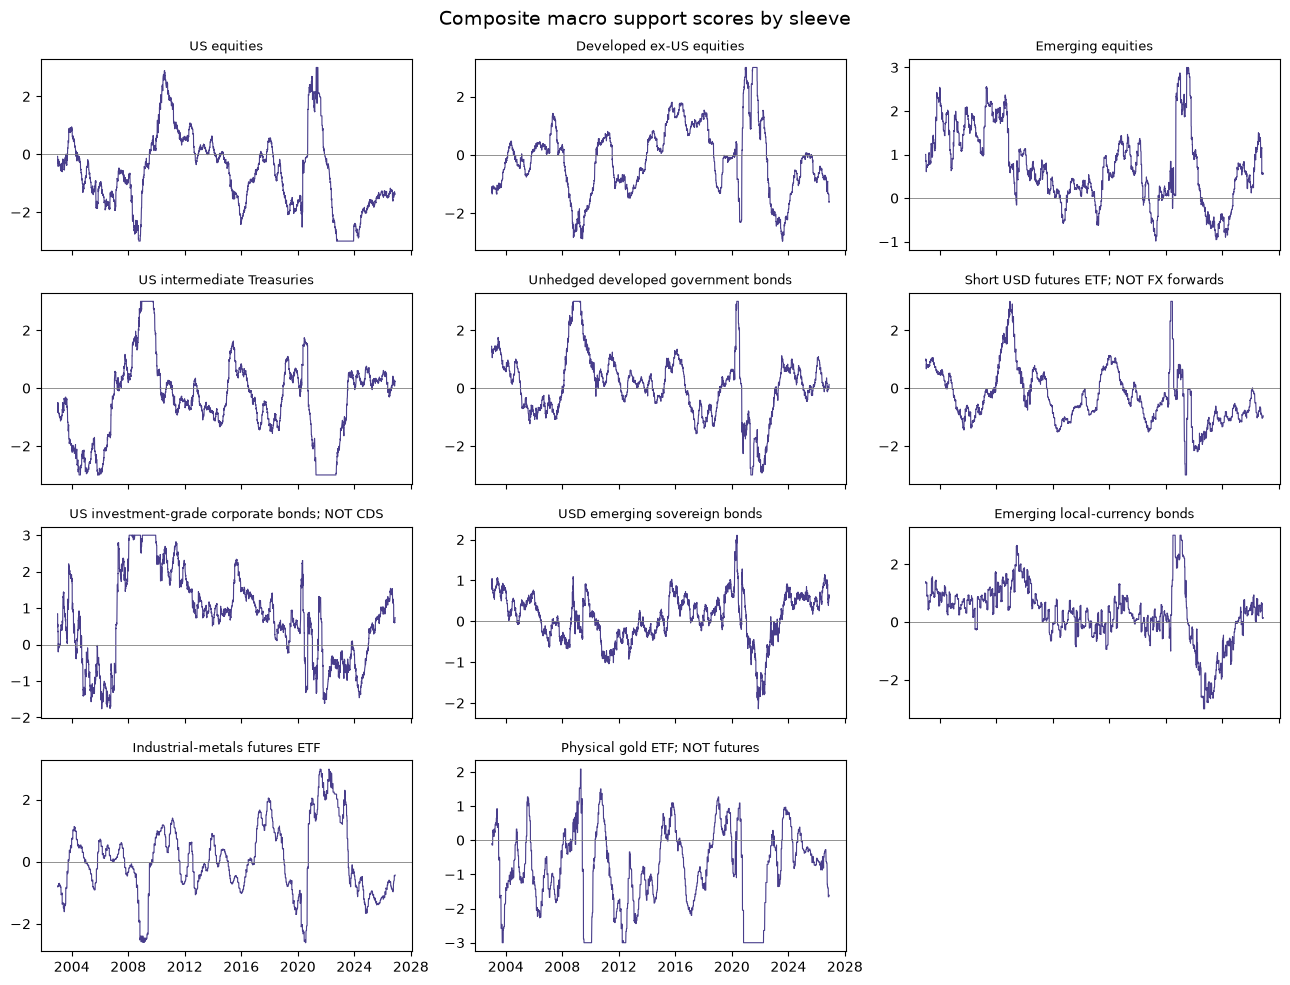

In [11]:
fig, axes = plt.subplots(4, 3, figsize=(13, 10), sharex=True)
wide_comp = dfx[dfx["xcat"] == "COMPOSITE_ZN"].pivot(
    index="real_date", columns="cid", values="value"
)[ASSET_CLASSES]
for ax, ac in zip(axes.flat, ASSET_CLASSES, strict=False):
    series = wide_comp[ac].loc["2003-01-01":]
    ax.plot(series.index, series.values, lw=0.8, color="darkslateblue")
    ax.axhline(0, color="gray", lw=0.6)
    ax.set_title(AC_LABELS[ac], fontsize=9)
axes.flat[-1].axis("off")
fig.suptitle("Macro support scores by asset class", fontsize=14)
plt.tight_layout()
plt.show()

## Theory-guided signal

### Specs and panel test

Quarter-end support scores are compared with next-quarter excess returns, pooled across asset classes. Quarters enter only once an asset class is live. Over 934 asset-class quarters the Pearson correlation has been 0.068 (p = 0.04) and the Kendall rank correlation 0.059 (p = 0.007). This is a typical magnitude for macro signals, whose value arises from many decisions over many years rather than from individual calls.

pooled observations: 934
Pearson r = 0.068 (p = 0.0377); Kendall tau = 0.059 (p = 0.0069)


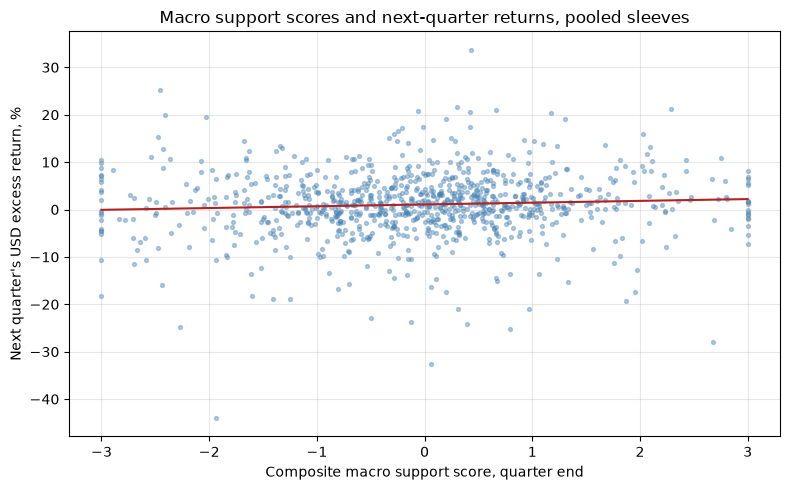

In [12]:
wide_xr = df_xr.pivot(index="real_date", columns="cid", values="value")
quarter_ends = wide_comp.resample("QE").last()
# min_count keeps quarters before a sleeve is live as missing; a plain sum
# would turn them into zero returns and pad the test with fake observations
next_quarter = (
    wide_xr.resample("QE").sum(min_count=20).shift(-1)
)
paired = pd.concat(
    [quarter_ends.stack().rename("score"), next_quarter.stack().rename("ret")],
    axis=1,
).dropna()
paired = paired[paired.index.get_level_values(0) >= START_DATE]
pearson_r, pearson_p = stats.pearsonr(paired["score"], paired["ret"])
tau, tau_p = stats.kendalltau(paired["score"], paired["ret"])
print(f"pooled observations: {len(paired)}")
print(f"Pearson r = {pearson_r:.3f} (p = {pearson_p:.4f}); "
      f"Kendall tau = {tau:.3f} (p = {tau_p:.4f})")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(paired["score"], paired["ret"], s=8, alpha=0.4, color="steelblue")
slope, intercept = np.polyfit(paired["score"], paired["ret"], 1)
grid = np.linspace(paired["score"].min(), paired["score"].max(), 50)
ax.plot(grid, intercept + slope * grid, color="firebrick", lw=1.5)
ax.set_xlabel("Composite macro support score, quarter end")
ax.set_ylabel("Next quarter's USD excess return, %")
ax.set_title("Macro support scores and next-quarter returns, pooled sleeves")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Learning-based signal generation

### Sequential learning

For each asset class, 35 models use all 74 factors at month-end to predict next month's vol-targeted return. Each model first condenses the features into 5 to 10 principal components and then applies Ridge, Lasso, time-weighted least squares or OLS regression.

Learning is sequential. Models are re-estimated every quarter with data available at the time, once 48 months of history exist. The forecast is an average of all 35 models, weighted by their predictive accuracy over three expanding validation periods. Forecasts start in 1994 for the longest histories and in 2015 for emerging local-currency bonds. The largest model weight has averaged about 0.045, close to an even 1/35 split, so no single specification dominates.

In [13]:
ML_MAX_ITER = 50_000
ML_RIDGE_ALPHAS = [10.0, 1_000.0]
ML_LASSO_ALPHAS = [0.01, 0.1]
ML_TWLS_HALF_LIVES = [60, 120]
ML_OLS_INTERCEPTS = [False]
ML_COMPONENTS = [5, 6, 7, 8, 10]
ML_N_MEMBERS = len(ML_COMPONENTS) * (
    len(ML_RIDGE_ALPHAS) + len(ML_LASSO_ALPHAS)
    + len(ML_TWLS_HALF_LIVES) + len(ML_OLS_INTERCEPTS)
)
ML_MIN_PERIODS = 48
print(f"{ML_N_MEMBERS} ensemble members per sleeve")

df_broadcast_features = wide_daily.reindex(columns=FACTS_BCAST)
rets_rf = [f"{ac}_XRVT" for ac in ASSET_CLASSES]
df_rf = dfx[(dfx["xcat"] == "XRVT") & (dfx["cid"].isin(ASSET_CLASSES))].copy()
df_rf["xcat"] = df_rf["cid"] + "_XRVT"
df_rf["cid"] = "GLB"
dfrf = df_rf[RNG_COLS].reset_index(drop=True)

35 ensemble members per sleeve


In [14]:
so_ml, ml_signals, ml_topw = {}, [], {}
df_model_features = df_broadcast_features.ffill().fillna(0.0)
assert not df_model_features.isna().any().any()
features_long = df_model_features.stack().rename("value").reset_index()
features_long.columns = ["real_date", "xcat", "value"]
features_long["cid"] = "GLB"
for asset_class in ASSET_CLASSES:
    df_target = dfrf.loc[dfrf["xcat"] == f"{asset_class}_XRVT", RNG_COLS]
    dfp_ml = pd.concat([features_long[RNG_COLS], df_target], ignore_index=True)

    signal_optimizer = msl.SignalOptimizer(
        df=dfp_ml,
        xcats=list(df_model_features.columns) + [f"{asset_class}_XRVT"],
        cids=["GLB"],
        freq="M",
        lag=1,
        xcat_aggs=["last", "sum"],
        drop_nas=True,
    )
    regressors = [
        (f"ridge_{alpha:g}", Ridge(alpha=alpha, fit_intercept=False))
        for alpha in ML_RIDGE_ALPHAS
    ]
    regressors += [
        (f"lasso_{alpha:g}", Lasso(alpha=alpha, fit_intercept=False,
                                   max_iter=ML_MAX_ITER))
        for alpha in ML_LASSO_ALPHAS
    ]
    regressors += [
        (f"twls_{half_life}",
         msl.TimeWeightedLinearRegression(fit_intercept=False, half_life=half_life))
        for half_life in ML_TWLS_HALF_LIVES
    ]
    regressors += [
        ("ols", LinearRegression(fit_intercept=intercept))
        for intercept in ML_OLS_INTERCEPTS
    ]
    members = [
        (
            f"pc{n}_{name}",
            Pipeline([
                ("pca", PCA(n_components=n, random_state=42)),
                ("reg", regressor),
            ]).set_output(transform="pandas"),
            {},
        )
        for n in ML_COMPONENTS
        for name, regressor in regressors
    ]
    signal_optimizer.calculate_predictions(
        name="ML",
        models={
            "AVG": msl.ModelAveragingRegressor(
                estimators=members,
                scoring=make_scorer(msl.correlation_coefficient),
                cv=msl.ExpandingKFoldPanelSplit(n_splits=3),
            )
        },
        hyperparameters=None,
        scorers=None,
        inner_splitters=None,
        store_additional_data=["weights_"],
        min_cids=1,
        min_periods=ML_MIN_PERIODS,
        test_size=3,
        n_jobs_outer=4,
    )
    so_ml[asset_class] = signal_optimizer
    dfa = signal_optimizer.get_optimized_signals()
    assert len(dfa), f"{asset_class}: no signal rows"
    assert np.isfinite(dfa["value"]).all(), f"{asset_class}: non-finite forecasts"
    dfa["cid"], dfa["xcat"] = asset_class, "ML_PRED"
    ml_signals.append(dfa[RNG_COLS])

    optimal = signal_optimizer.get_optimal_models("ML")
    weight_rows = pd.DataFrame([
        details["weights_"]
        for details in optimal["additional_data"]
        if isinstance(details, dict) and isinstance(details.get("weights_"), dict)
    ])
    assert weight_rows.shape[1] == ML_N_MEMBERS, (
        f"{asset_class}: {weight_rows.shape[1]} member weights"
    )
    ml_topw[asset_class] = float(weight_rows.max(axis=1).mean())
    first = dfa["real_date"].min().date()
    print(f"{asset_class}: {len(dfa):,} forecast days from {first}; "
          f"mean top member weight {ml_topw[asset_class]:.3f}")

dfx = msm.update_df(dfx, pd.concat(ml_signals, ignore_index=True))

100%|██████████| 117/117 [01:07<00:00,  1.73it/s]


USEQ: 7,587 forecast days from 1997-10-31; mean top member weight 0.045


100%|██████████| 104/104 [00:51<00:00,  2.03it/s]


DXEQ: 6,783 forecast days from 2000-11-30; mean top member weight 0.045


100%|██████████| 104/104 [00:51<00:00,  2.02it/s]


EMEQ: 6,783 forecast days from 2000-11-30; mean top member weight 0.045


... (12 outputs left out)

100%|██████████| 61/61 [00:29<00:00,  2.10it/s]


MTL: 3,957 forecast days from 2011-09-30; mean top member weight 0.046


100%|██████████| 70/70 [00:33<00:00,  2.07it/s]


GLD: 4,522 forecast days from 2009-07-31; mean top member weight 0.047


### Forecast accuracy and correlation check

Monthly out-of-sample forecasts are compared with realized vol-targeted returns for each asset class. The correlation indicates directional accuracy. The error ratio compares forecast errors with those of a zero forecast, with values below 1 favoring the model.

Ten of eleven forecasts have been positively correlated with subsequent monthly returns, from 0.001 for emerging credit to 0.095 for developed FX. None has outperformed a zero forecast on squared error, as forecast variation has been large relative to the predictive edge. This matters less for allocation, since weights are based on re-scored signals and the raw size of each forecast drops out.

In [15]:
wide_pred = dfx[dfx["xcat"] == "ML_PRED"].pivot(
    index="real_date", columns="cid", values="value"
)
target_m = (
    dfx[(dfx["xcat"] == "XRVT") & (dfx["cid"].isin(ASSET_CLASSES))]
    .pivot(index="real_date", columns="cid", values="value")
    .resample("ME").sum(min_count=15)
)
pred_m = wide_pred.resample("ME").last()
quality = []
for ac in ASSET_CLASSES:
    pair = pd.concat(
        [pred_m[ac].shift(1).rename("pred"), target_m[ac].rename("real")], axis=1
    ).dropna()
    if len(pair) < 12:
        continue
    rmse = float(np.sqrt(((pair["real"] - pair["pred"]) ** 2).mean()))
    rmse_zero = float(np.sqrt((pair["real"] ** 2).mean()))
    quality.append({
        "sleeve": ac,
        "months": len(pair),
        "corr": round(float(pair["pred"].corr(pair["real"])), 3),
        "rmse_vs_zero": round(rmse / rmse_zero, 3),
    })
df_quality = pd.DataFrame(quality).set_index("sleeve")
print(df_quality.to_string())
beats_zero = int((df_quality["rmse_vs_zero"] < 1).sum())
print(f"learning beats the zero forecast in {beats_zero} of {len(df_quality)} sleeves")

        months   corr  rmse_vs_zero
sleeve                             
USEQ       348  0.087         1.014
DXEQ       311  0.035         1.018
EMEQ       311  0.010         1.031
USDU       385  0.050         1.019
DXDU       172  0.053         1.004
DXFX       385  0.095         1.008
G2CR       385  0.072         1.029
EMCR       170  0.001         1.030
EMLC       138 -0.091         1.041
MTL        181  0.040         1.017
GLD        207  0.059         1.006
learning beats the zero forecast in 0 of 11 sleeves


### Allocation weights

Learned forecasts and theory-guided scores are translated into weights by the same rule. Month-end signals are scored and passed through a softmax function: each asset class receives a weight proportional to the exponential of its score, with cash competing at a score of zero. Weights are positive and sum to one, and cash rises when all asset classes score poorly.

The chart below shows weights over time. The theory-guided allocation shifted towards emerging equities in 2005–07, towards credit after 2009 and towards metals in 2021–23, and reduced equity exposure in 2008 and 2022. The learning-based allocation starts earlier, rotates more frequently and held more duration and FX in its early years.

In [16]:
pred_counts = dfx[dfx["xcat"] == "ML_PRED"].groupby("cid")["value"].size()
cids_pred = [ac for ac in ASSET_CLASSES if pred_counts.get(ac, 0) >= 3 * 261 + 60]
assert cids_pred, "no sleeve has enough forecast history to score"
if set(cids_pred) != set(ASSET_CLASSES):
    short = sorted(set(ASSET_CLASSES) - set(cids_pred))
    print(f"forecast scores unavailable for {short}")
dfa = msp.make_zn_scores(
    df=dfx, xcat="ML_PRED", cids=cids_pred, neutral="zero", thresh=3,
    est_freq="M", min_obs=3 * 261, pan_weight=0, postfix="_ZN",
)
dfx = msm.update_df(dfx, dfa)


def softmax_weights(score_xcat: str) -> pd.DataFrame:
    scores = (
        dfx[(dfx["xcat"] == score_xcat) & (dfx["cid"].isin(ASSET_CLASSES))]
        .pivot(index="real_date", columns="cid", values="value")
        .reindex(columns=ASSET_CLASSES)
        .dropna(how="all")
    )
    month_end = scores.groupby([scores.index.year, scores.index.month]).tail(1)
    live = (
        wide_xr.notna().reindex(month_end.index, method="ffill")
        .reindex(columns=month_end.columns).fillna(False)
    )
    logits = month_end.where(live)
    logits["CASH"] = 0.0
    exponent = np.exp(logits)
    return exponent.div(exponent.sum(axis=1), axis=0).fillna(0.0)


w_macro = softmax_weights("COMPOSITE_ZN")
w_ml = softmax_weights("ML_PRED_ZN")

bdays_all = pd.DatetimeIndex(
    sorted(dfx.loc[dfx["xcat"] == "XR_NSA", "real_date"].unique())
)
live_daily = (
    wide_xr.notna().reindex(bdays_all, method="ffill")
    .reindex(columns=ASSET_CLASSES).fillna(False)
)
live_daily["CASH"] = True
w_equal = live_daily.div(live_daily.sum(axis=1), axis=0)

for weights, xcat in ((w_macro, "WGTMACRO"), (w_ml, "WGTML"), (w_equal, "WGTEQUAL")):
    daily = weights.reindex(bdays_all).ffill().dropna(how="all")
    dfa = daily.stack().rename("value").reset_index()
    dfa.columns = ["real_date", "cid", "value"]
    dfa["xcat"] = xcat
    dfx = msm.update_df(dfx, dfa[RNG_COLS])

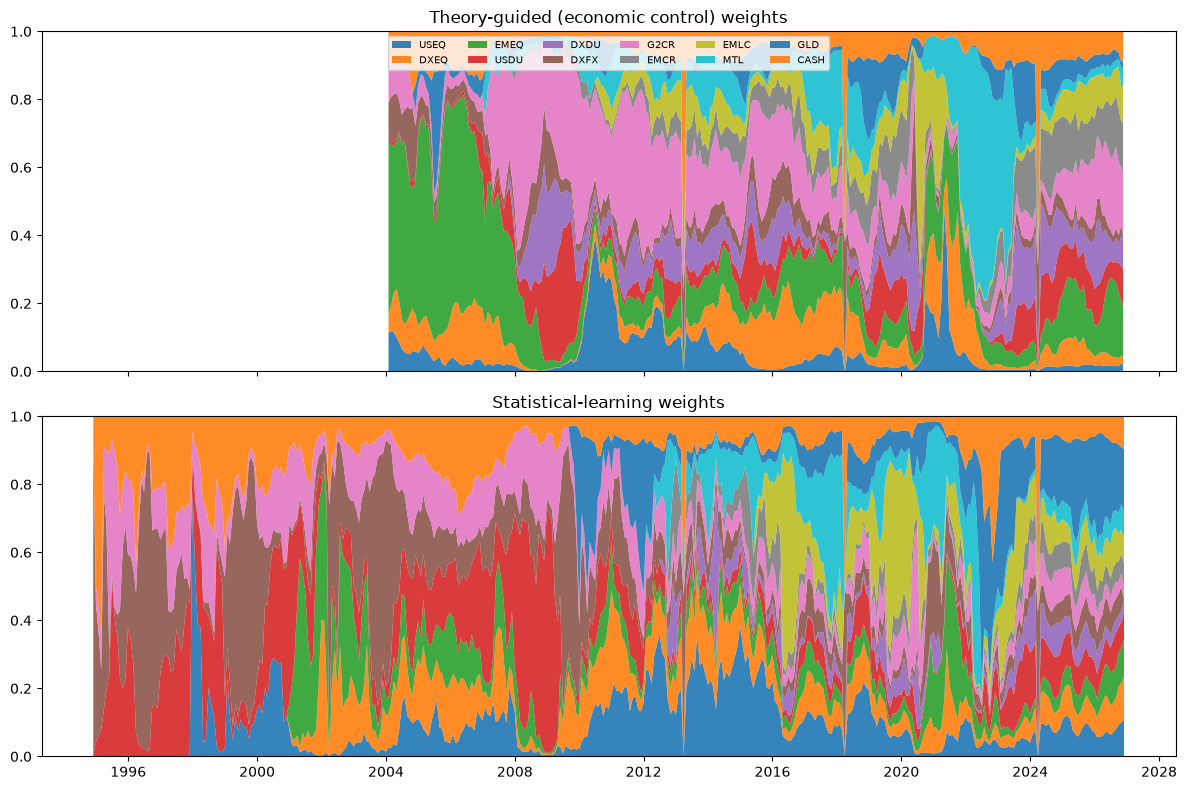

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, (weights, title) in zip(axes, [
    (w_macro.loc[START_DATE:], "Theory-guided (economic control) weights"),
    (w_ml.dropna(how="all"), "Statistical-learning weights"),
], strict=True):
    cols = ASSET_CLASSES + ["CASH"]
    ax.stackplot(weights.index, [weights[c].fillna(0) for c in cols],
                 labels=cols, alpha=0.9)
    ax.set_ylim(0, 1)
    ax.set_title(title)
axes[0].legend(ncol=6, fontsize=7, loc="upper center")
plt.tight_layout()
plt.show()

## Value checks

### Naive PnL

Naive PnLs apply the weights to excess returns with quarterly rebalancing and a one-day slippage between signal and position. They do not include transaction costs or risk management and therefore measure the signal itself. The benchmark is an equal allocation across live asset classes and cash.

Since 2004 the theory-guided allocation has produced a Sharpe ratio of 0.60, the learning-based allocation 0.52 and equal weights 0.50. Both macro allocations have had correlations of about 0.58 with US equity returns, against 0.77 for equal weights. The learning-based allocation has slightly improved on equal weights and has had the smallest peak-to-trough drawdown, at −29% versus −32% for the other two. Both macro allocations have taken over four years to recover from their largest drawdown, against 16 months for equal weights.

In [18]:
cidx = ASSET_CLASSES + ["CASH"]
xpnl = msn.NaivePnL(
    dfx, ret="XR_NSA", sigs=["WGTMACRO", "WGTEQUAL", "WGTML"],
    cids=cidx, start=START_DATE, bms=["USEQ_XR_NSA"],
)
for sig, name in (("WGTMACRO", "PNL_MACRO"), ("WGTEQUAL", "PNL_EQUAL"),
                  ("WGTML", "PNL_ML")):
    xpnl.make_pnl(
        sig=sig, sig_op="raw", rebal_freq="quarterly", rebal_slip=1,
        vol_scale=None, pnl_name=name,
    )
pnl_stats = xpnl.evaluate_pnls(pnl_cats=["PNL_MACRO", "PNL_EQUAL", "PNL_ML"])
print(pnl_stats.to_string())

xcat                        PNL_MACRO  PNL_EQUAL     PNL_ML
Return %                     5.651328    4.33221   4.426769
St. Dev. %                   9.452051   8.615646   8.588129
Sharpe Ratio                 0.597894   0.502831   0.515452
Sortino Ratio                0.839905   0.705482   0.716359
Max 21-Day Draw %          -18.375908  -22.13369 -18.368756
Max 6-Month Draw %         -30.885679 -31.653232 -28.458876
Peak to Trough Draw %      -31.982112 -32.438184 -29.069728
Top 5% Monthly PnL Share     0.692052   0.763129   0.706926
USEQ_XR_NSA correl           0.578367   0.770314   0.594528
Sharpe Stability Ratio        4.49998   4.034877   4.110871
Max Draw Recovery (months)  55.666667  16.095238   54.47619
Prob. Sharpe Ratio > 0.25    0.998514   0.993488   0.994118
Prob. Sharpe Ratio > 0.5     0.925238   0.824159   0.823144
Prob. Sharpe Ratio > 0.75     0.46487   0.267484   0.253244
Traded Months                     272        272        272


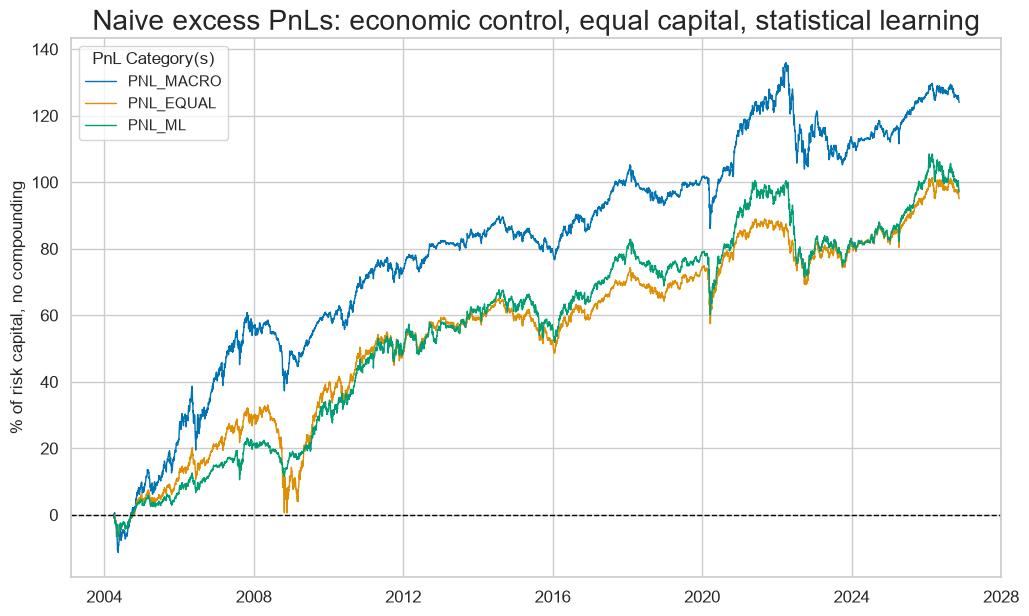

In [19]:
xpnl.plot_pnls(
    pnl_cats=["PNL_MACRO", "PNL_EQUAL", "PNL_ML"],
    title="Naive excess PnL by allocation",
    xcat_labels=["Theory-guided", "Equal weights", "Statistical learning"],
)

### Consistency of the value-add

Performance is compared over the full sample and over the period since mid-2010, when all eleven asset classes trade. Over the full sample the theory-guided allocation has posted a Sharpe ratio of 0.61, and the learning-based allocation has slightly improved on equal weights with 0.53 against 0.52. Since mid-2010 the theory-guided allocation has matched equal weights at 0.47, while the learning-based allocation has been marginally lower at 0.44 but with a higher annual return of 3.98% against 3.62%. Most of the return advantage has therefore accrued between 2004 and 2010, when fewer asset classes were live.

In [20]:
all_live = wide_xr.apply(lambda col: col.first_valid_index()).max()
windows = {
    "2004-10 to 2026-10": ("2004-10-29", "2026-10-31"),
    f"all sleeves live ({all_live:%Y-%m})": (f"{all_live:%Y-%m-%d}", "2026-10-31"),
}
rows = []
for label, (start, end) in windows.items():
    ev = xpnl.evaluate_pnls(pnl_cats=["PNL_MACRO", "PNL_ML", "PNL_EQUAL"],
                            start=start, end=end)
    for book in ["PNL_MACRO", "PNL_ML", "PNL_EQUAL"]:
        rows.append({"window": label, "book": book,
                     "Sharpe": round(float(ev.loc["Sharpe Ratio", book]), 2),
                     "Return %": round(float(ev.loc["Return %", book]), 2),
                     "St. Dev. %": round(float(ev.loc["St. Dev. %", book]), 2)})
df_windows = pd.DataFrame(rows).set_index(["window", "book"])
print(df_windows.to_string())

                                      Sharpe  Return %  St. Dev. %
window                     book                                   
2004-10 to 2026-10         PNL_MACRO    0.61      5.77        9.38
                           PNL_ML       0.53      4.55        8.60
                           PNL_EQUAL    0.52      4.48        8.64
all sleeves live (2010-07) PNL_MACRO    0.47      4.02        8.63
                           PNL_ML       0.44      3.98        8.98
                           PNL_EQUAL    0.47      3.62        7.65


### Wealth generation with compounding

Total returns add back the cash rate and compound daily. Month-end weights apply from the next session, so all allocations could have been implemented in real time. The theory-guided allocation has compounded at 6.9% a year, against 5.8% for the learning-based allocation and 5.6% for equal weights. The learning-based allocation has thus added a slight improvement over equal weights in wealth terms, with the smallest drawdown at −21% against −27% and −28%.

                           start  CAGR %  Sharpe (excess)  Sortino  max drawdown %
book                                                                              
Economic control      2004-01-02    6.92            0.557    0.710           -27.4
Statistical learning  2004-01-02    5.76            0.484    0.638           -21.3
Equal capital         2004-01-02    5.60            0.459    0.602           -28.3


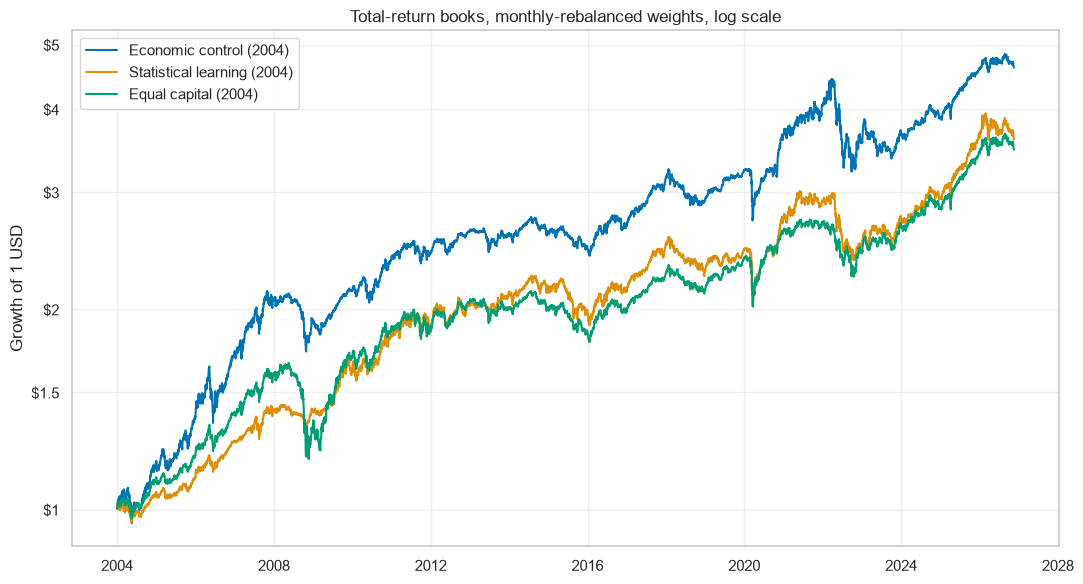

In [21]:
total_returns = wide_xr.add(cash_accrual, axis=0)
total_returns["CASH"] = cash_accrual
books = {}
for name, weights in (("Theory-guided", w_macro),
                      ("Statistical learning", w_ml),
                      ("Equal weights", w_equal)):
    daily_w = weights.reindex(bdays_all).ffill().shift(1)
    cols = [c for c in daily_w.columns if c in total_returns.columns]
    daily_ret = (daily_w[cols] * total_returns[cols].fillna(0.0) / 100.0).sum(axis=1)
    daily_ret = daily_ret[daily_ret.index >= START_DATE]
    first_live = daily_w.dropna(how="all").index.min()
    daily_ret = daily_ret[daily_ret.index >= first_live]
    books[name] = daily_ret

summary_rows = []
for name, returns in books.items():
    wealth = (1 + returns).cumprod()
    years = (returns.index[-1] - returns.index[0]).days / 365.25
    cagr = 100.0 * (wealth.iloc[-1] ** (1 / years) - 1)
    excess = returns - cash_accrual.reindex(returns.index).fillna(0.0) / 100.0
    sharpe = float(excess.mean() / excess.std() * np.sqrt(252))
    downside = excess[excess < 0]
    sortino = float(excess.mean() / downside.std() * np.sqrt(252))
    drawdown = 100.0 * float((wealth / wealth.cummax() - 1).min())
    summary_rows.append({
        "book": name, "start": returns.index[0].date(), "CAGR %": round(cagr, 2),
        "Sharpe (excess)": round(sharpe, 3), "Sortino": round(sortino, 3),
        "max drawdown %": round(drawdown, 1),
    })
df_summary = pd.DataFrame(summary_rows).set_index("book")
print(df_summary.to_string())

fig, ax = plt.subplots(figsize=(11, 6))
for name, returns in books.items():
    wealth = (1 + returns).cumprod()
    ax.plot(wealth.index, wealth.values, label=f"{name} ({returns.index[0].year})")
ax.set_yscale("log")
# plain dollar ticks instead of 10^0 and 2x10^0 labels
ax.yaxis.set_major_locator(mticker.FixedLocator([1, 1.5, 2, 3, 4, 5, 6]))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:g}"))
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_title("Growth of 1 USD by allocation, monthly-rebalanced weights, log scale")
ax.set_ylabel("Growth of 1 USD")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()